# Azure Functions Invocation Trace 2021

Что это за данные

Microsoft выложила журнал работы своих облачных функций за 2 недели. Каждая строка это одно событие: «какая-то программа что-то сделала». Например, пришёл заказ и его обработали. Про каждое событие известно два числа:

когда оно закончилось;
сколько оно длилось.

Если из времени окончания вычесть длительность, получается время, когда событие пришло

| | |
|---|---|
| **Источник** | [Azure/AzurePublicDataset](https://github.com/Azure/AzurePublicDataset/blob/master/AzureFunctionsInvocationTrace2021.md) |
| **Статья** | Zhang et al. *Faster and Cheaper Serverless Computing on Harvested Resources*, **SOSP 2021** |
| **Период** | 2 недели, начиная с 31.01.2021 |
| **Объём** | ~2 млн вызовов, архив 18 МБ (305 МБ в распакованном виде) |


**Поля:** `app` - приложение (хеш), `func` — функция (хеш), `end_timestamp` — время окончания вызова в секундах от начала трейса, `duration` — длительность вызова в секундах


>По документации, метки времени сдвинуты относительно реального продакшена. Поэтому привязка к конкретному часу суток условна, но форма нагрузки (циклы, всплески) сохраняется

In [ ]:
# Общие настройки: библиотеки, стиль графиков, функция загрузки
import os, urllib.request, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 30)


C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6']
ANOM = '#e34948'
plt.rcParams.update({
    'figure.figsize': (12, 3.6), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.6,
    'axes.edgecolor': '#8a8984', 'axes.titleweight': 'bold', 'axes.titlesize': 11,
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'lines.linewidth': 1.2, 'axes.prop_cycle': plt.cycler(color=C), 'axes.axisbelow': True,
    'legend.frameon': False,
})
import matplotlib.dates as mdates

def fmt_dates(ax, fmt='%d.%m'):
    """Компактные подписи дат на оси X."""
    loc = mdates.AutoDateLocator(minticks=5, maxticks=10)
    ax.xaxis.set_major_locator(loc)
    ax.xaxis.set_major_formatter(mdates.DateFormatter(fmt))

def download(url, path, retries=3):
    """Скачивает файл, если его ещё нет; проверяет размер и повторяет при обрыве связи."""
    os.makedirs(os.path.dirname(path) or '.', exist_ok=True)
    if not os.path.exists(path):
        print('Скачиваю', url)
        for attempt in range(1, retries + 1):
            try:
                with urllib.request.urlopen(url, timeout=120) as r, open(path + '.part', 'wb') as f:
                    expected = int(r.headers.get('Content-Length') or 0)
                    while chunk := r.read(1 << 20):
                        f.write(chunk)
                if expected and os.path.getsize(path + '.part') != expected:
                    raise IOError('файл скачался не полностью')
                os.replace(path + '.part', path)
                break
            except Exception as e:
                print(f'  попытка {attempt} не удалась: {e}')
                if attempt == retries: raise
    print(f'{path}: {os.path.getsize(path)/1e6:.1f} МБ')

# 1. Загрузка

Скачиваем архив с GitHub, распаковываем и читаем таблицу. В ней около 2 млн строк.

In [ ]:
DATA = 'data/azure_functions_2021'
RAR = f'{DATA}/AzureFunctionsInvocationTraceForTwoWeeksJan2021.rar'
TXT = f'{DATA}/AzureFunctionsInvocationTraceForTwoWeeksJan2021.txt'
URL = 'https://raw.githubusercontent.com/Azure/AzurePublicDataset/master/data/AzureFunctionsInvocationTraceForTwoWeeksJan2021.rar'

import shutil, subprocess
if not os.path.exists(TXT):
    download(URL, RAR)
    if shutil.which('unrar') is None:                      # в Colab unrar обычно уже есть
        subprocess.run('apt-get -qq update && apt-get -qq install -y unrar', shell=True)
    r = subprocess.run(['unrar', 'x', '-o+', RAR, DATA + '/'], capture_output=True, text=True)
    print(r.stdout[-300:], r.stderr[-300:])
    if not os.path.exists(TXT):
        raise RuntimeError('Архив не распаковался: см. сообщение unrar выше')
print('Распакованный файл:', os.path.getsize(TXT) / 1e6, 'МБ')

Распакованный файл: 305.388316 МБ


In [ ]:
df = pd.read_csv(TXT).dropna()
df['start'] = df['end_timestamp'] - df['duration']      # время прихода события
df = df[df['start'] >= 0]
print(df.shape)
df.head()

(1980951, 5)


,app,func,end_timestamp,duration,start
0,7b2c43a2bc30f6bb438074df88b603d2cb982d3e7961de...,e3cdb48830f66eb8689cc0223514569a69812b77e6611e...,0.079491,0.078,0.001491
1,1573b95c039e51cc012b543a4af3bc7c3ee9485acbb003...,337cd24a7d5fd5c92460faee4ebe6a186a0eb322bd17b7...,57.157860,57.154,0.003860
2,1573b95c039e51cc012b543a4af3bc7c3ee9485acbb003...,48cc770d590d3c5a7691b3b4e9302f82ec3be5ddc2a037...,59.130478,59.125,0.005478
3,f274d71de386ccc77e4ca74766dbc485461c3053059d47...,3d2aee54a133509f16fb636d74128c2adcfcac71c6dcef...,6.252541,6.236,0.016541
4,7b2c43a2bc30f6bb438074df88b603d2cb982d3e7961de...,68bbfd828223a505d7917339f4656c5f33ff93225cdb9d...,0.066824,0.050,0.016824


# 2. Проверка данных

Смотрим, всё ли в порядке:


*   пропусков нет
*   есть ~2,6 тыс. повторяющихся строк
*   119 приложений, 424 функции
*   период ровно 14 дней

In [ ]:
print('Типы:\n', df.dtypes, '\n')
print('Пропуски:', int(df.isna().sum().sum()))
print('Дубликаты:', int(df.duplicated().sum()))
print('Приложений:', df['app'].nunique(), '| функций:', df.groupby(['app', 'func']).ngroups)
print(f"Период: {df['start'].min()/86400:.2f} – {df['end_timestamp'].max()/86400:.2f} сут")
print(f"Средний поток: {len(df)/df['end_timestamp'].max():.2f} вызова/с")
df[['duration']].describe(percentiles=[.5, .9, .99]).T

Типы:
 app               object
func              object
end_timestamp    float64
duration         float64
start            float64
dtype: object 

Пропуски: 0
Дубликаты: 2606
Приложений: 119 | функций: 424
Период: 0.00 – 14.00 сут
Средний поток: 1.64 вызова/с


,count,mean,std,min,50%,90%,99%,max
duration,1980951.0,3.347944,18.507169,0.0,0.031,1.62,72.1995,578.62


# 3. Входящий поток: сколько событий приходит

Считаем, сколько событий пришло в каждую минуту

**Первый график** это нагрузка за 14 дней. Обычно приходит до 200 событий в минуту, но иногда бывают всплески до 3 тыс. Пик в 34 раза больше среднего

**Второй график** это средняя нагрузка по часам и дням недели. С понедельника по среду нагрузка в 2–3 раза выше, чем в выходные. Суточный цикл слабый, к тому же Microsoft сдвинула время, так что часы условные

**Третий график** это автокорреляция, то есть насколько текущая минута похожа на прошлые. Нагрузка сейчас сильно похожа на нагрузку минуту и пять минут назад. Вывод: прогноз на 5–15 минут вперёд вполне реален

count    20159.0
mean        98.3
std        149.4
min          0.0
50%         58.0
90%        203.0
99%        812.4
max       3358.0
Name: events_per_min, dtype: float64
Пик / среднее = 34.2,  коэффициент вариации = 1.52


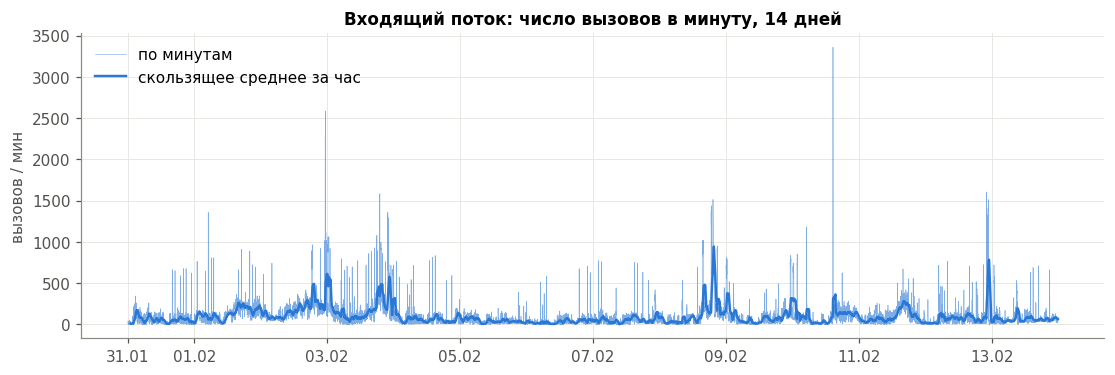

In [ ]:
T0 = pd.Timestamp('2021-01-31')
df['ts'] = T0 + pd.to_timedelta(df['start'], unit='s')
lam = df.set_index('ts').resample('1min').size().rename('events_per_min')
lam = lam.iloc[:-1]                                   # последняя минута неполная
print(lam.describe(percentiles=[.5, .9, .99]).round(1))
print(f'Пик / среднее = {lam.max()/lam.mean():.1f},  коэффициент вариации = {lam.std()/lam.mean():.2f}')

fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(lam.index, lam.values, lw=0.4, color=C[0], alpha=0.6, label='по минутам')
ax.plot(lam.rolling(60).mean(), lw=1.6, color=C[0], label='скользящее среднее за час')
ax.set_title('Входящий поток: число вызовов в минуту, 14 дней')
ax.set_ylabel('вызовов / мин'); ax.legend(loc='upper left'); fmt_dates(ax)
plt.show()

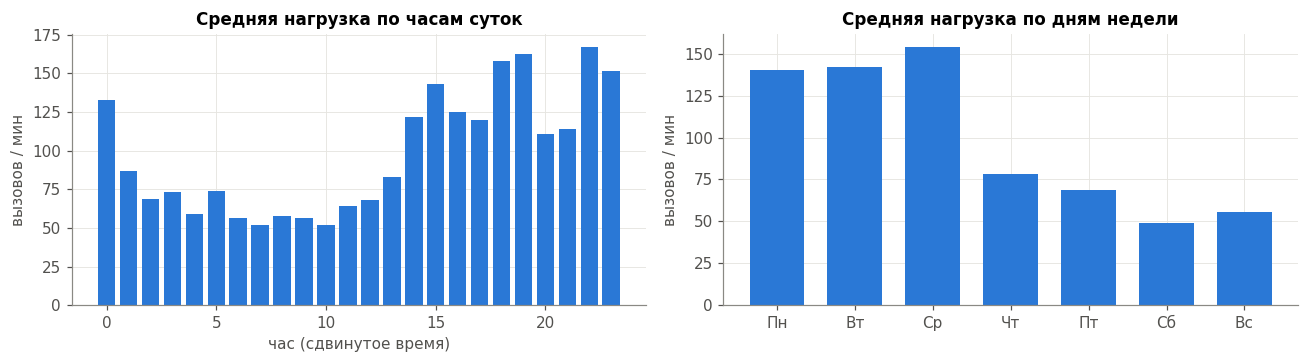

ts
Sun 31.01     56.2
Mon 01.02    136.0
Tue 02.02    191.9
Wed 03.02    201.2
Thu 04.02     63.6
Fri 05.02     44.0
Sat 06.02     32.4
Sun 07.02     54.8
Mon 08.02    144.7
Tue 09.02     92.4
Wed 10.02    106.7
Thu 11.02     92.5
Fri 12.02     94.0
Sat 13.02     65.3


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
hourly = lam.groupby(lam.index.hour).mean()
axes[0].bar(hourly.index, hourly.values, color=C[0], width=0.8)
axes[0].set_title('Средняя нагрузка по часам суток'); axes[0].set_xlabel('час (сдвинутое время)'); axes[0].set_ylabel('вызовов / мин')
names = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
daily = lam.groupby(lam.index.dayofweek).mean()
axes[1].bar([names[i] for i in daily.index], daily.values, color=C[0], width=0.7)
axes[1].set_title('Средняя нагрузка по дням недели'); axes[1].set_ylabel('вызовов / мин')
plt.tight_layout(); plt.show()

per_day = lam.resample('1D').mean().round(1)
per_day.index = per_day.index.strftime('%a %d.%m'); print(per_day.to_string())

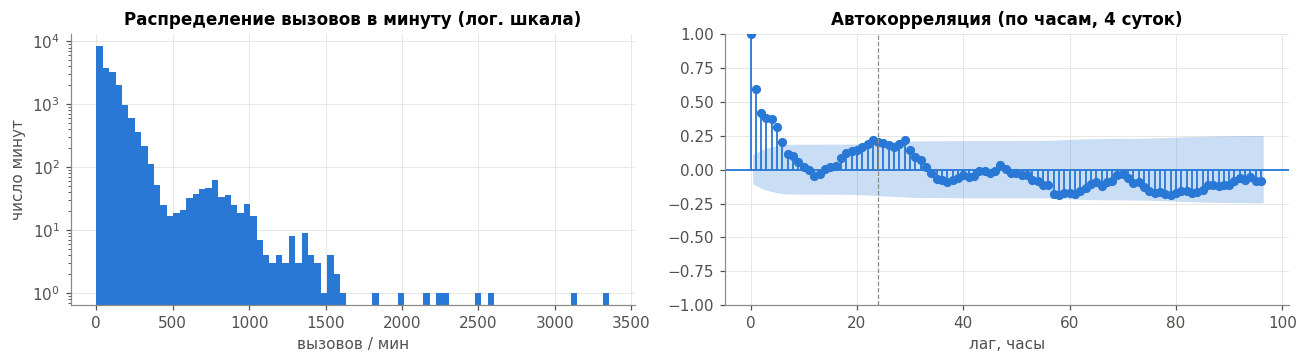

Автокорреляция поминутного ряда на лаге    1 мин: 0.86
Автокорреляция поминутного ряда на лаге    5 мин: 0.63
Автокорреляция поминутного ряда на лаге   60 мин: 0.30
Автокорреляция поминутного ряда на лаге 1440 мин: 0.12


In [ ]:
from statsmodels.graphics.tsaplots import plot_acf
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].hist(lam.values, bins=80, color=C[0])
axes[0].set_yscale('log'); axes[0].set_title('Распределение вызовов в минуту (лог. шкала)')
axes[0].set_xlabel('вызовов / мин'); axes[0].set_ylabel('число минут')
lam_h = lam.resample('1h').mean()
plot_acf(lam_h, lags=24 * 4, ax=axes[1], color=C[0], vlines_kwargs={'colors': C[0]}, title='Автокорреляция (по часам, 4 суток)')
axes[1].set_xlabel('лаг, часы'); axes[1].axvline(24, color='#8a8984', ls='--', lw=0.8)
plt.tight_layout(); plt.show()
for lag in [1, 5, 60, 1440]:
    print(f'Автокорреляция поминутного ряда на лаге {lag:>4} мин: {lam.autocorr(lag):.2f}')

# 4. Время обработки: как быстро работают обработчики

Гистограмма длительности: половина событий обрабатывается быстрее 31 миллисекунды, но 1% длится больше минуты, разброс огромный

График «топ-N приложений»: 3 приложения из 119 дают 59% всей нагрузки

График «сколько обработчиков занято одновременно»: средняя очередь = поток × время обработки прикидываем, сколько консьюмеров нужно в каждую минуту
Обычно хватает 1–6, а в пиках нужны сотни

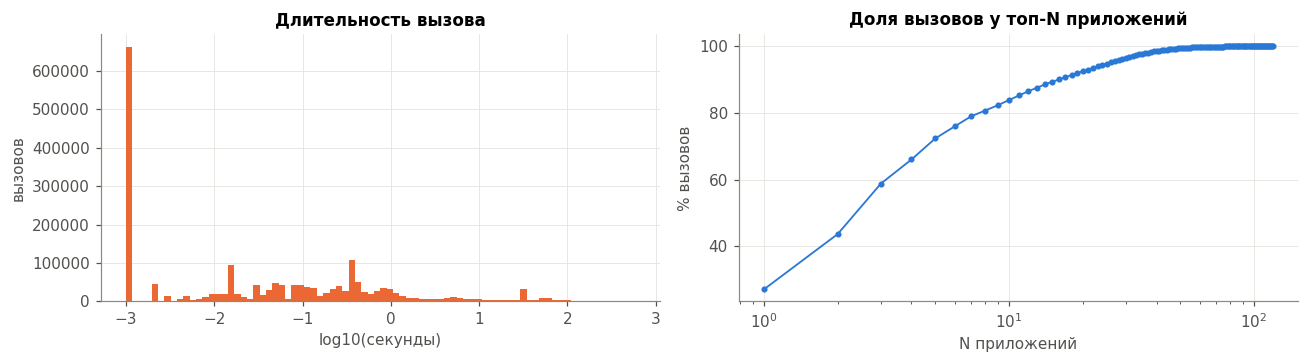

Медиана длительности 0.031 с, среднее 3.35 с, 99-й перцентиль 72.2 с
Вызовов короче 1 мс: 33% (на гистограмме это столбик слева)
Топ-3 приложения дают 59% вызовов, топ-10 — 84%


In [ ]:
d = df['duration'].clip(lower=1e-3)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].hist(np.log10(d), bins=80, color=C[1])
axes[0].set_title('Длительность вызова'); axes[0].set_xlabel('log10(секунды)'); axes[0].set_ylabel('вызовов')
share = df.groupby('app').size().sort_values(ascending=False)
cum = share.cumsum() / share.sum()
axes[1].plot(np.arange(1, len(cum) + 1), cum.values * 100, color=C[0], marker='o', ms=3)
axes[1].set_title('Доля вызовов у топ-N приложений'); axes[1].set_xlabel('N приложений'); axes[1].set_ylabel('% вызовов')
axes[1].set_xscale('log')
plt.tight_layout(); plt.show()
print(f'Медиана длительности {df.duration.median():.3f} с, среднее {df.duration.mean():.2f} с, 99-й перцентиль {df.duration.quantile(.99):.1f} с')
print(f'Вызовов короче 1 мс: {(df.duration <= 0.001).mean()*100:.0f}% (на гистограмме это столбик слева)')
print(f'Топ-3 приложения дают {cum.iloc[2]*100:.0f}% вызовов, топ-10 — {cum.iloc[9]*100:.0f}%')

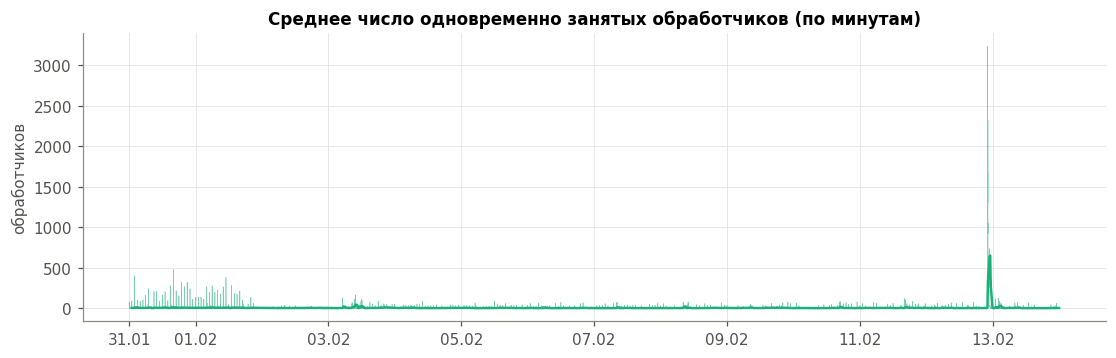

count    20159.0
mean         5.5
std         54.9
min          0.0
50%          1.2
90%          6.2
99%         62.6
max       3235.7
Name: duration, dtype: float64
Корреляция числа вызовов и занятости: 0.27


In [ ]:
# Если колонки со временем ещё нет — создаём её (на случай запуска не по порядку)
T0 = pd.Timestamp('2021-01-31')
if 'ts' not in df.columns:
    df['ts'] = T0 + pd.to_timedelta(df['start'], unit='s')
if 'lam' not in globals():
    lam = df.set_index('ts').resample('1min').size().iloc[:-1]

busy = (df.set_index('ts')['duration'].resample('1min').sum() / 60).iloc[:-1]
fig, ax = plt.subplots(figsize=(12, 3.4))
ax.plot(busy.index, busy.values, lw=0.4, color=C[2], alpha=0.6)
ax.plot(busy.rolling(60).mean(), lw=1.6, color=C[2])
ax.set_title('Среднее число одновременно занятых обработчиков (по минутам)')
ax.set_ylabel('обработчиков'); fmt_dates(ax)
plt.show()
print(busy.describe(percentiles=[.5, .9, .99]).round(1))
print(f'Корреляция числа вызовов и занятости: {lam.corr(busy):.2f}')

## 5. Выводы

**Что увидели**
- **2 млн вызовов за 14 дней**, в среднем ~98 вызовов в минуту (1,6 в секунду). Пропусков нет, ~2,6 тыс. полных дубликатов строк.
- **Нагрузка очень неравномерная:** пик в 34 раза выше среднего, коэффициент вариации 1,5. Распределение с тяжёлым хвостом: обычно до 200 вызовов в минуту, но бывают минуты с 1–3 тыс.
- **Есть недельный цикл:** понедельник–среда в 2–3 раза нагруженнее, чем выходные. Суточный цикл есть, но слабый (автокорреляция на 24 часа ≈ 0,2), а часы сдвинуты, так что к реальному времени суток не привязываемся.
- **Ряд хорошо помнит ближайшее прошлое:** автокорреляция 0,86 на 1 минуту и 0,63 на 5 минут. Значит, прогноз на 5–15 минут вперёд реален.
- **Время обработки сильно различается:** медиана 31 мс, но 99-й перцентиль 72 с; треть вызовов короче 1 мс. Обработчиков нужно в среднем 5, но в пиках до сотен.
- **Нагрузка сконцентрирована:** 3 приложения из 119 дают 59% вызовов.

**Плюсы для проекта**
- Есть и время прихода, и время обработки каждого события
- Много резких всплесков: хорошо для задач «перегружен / не перегружен» и прогноза пиков.

**Минусы**
- Всего 2 недели: недельный цикл виден только дважды.
- Время сдвинуто, нет праздников и привязки к реальным событиям.
- Один сервис, без цепочки зависимостей.

